# 03 · Overview of surnames (Censo 2022)

Loads `data/nomes_censo2022_sobrenomes.jsonl` and visualises the most common
surnames, their share of the population, and how concentrated the surname
distribution is.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebooks live in test/; the datasets live in ../data/
DATA = Path("..") / "data"
NOMES_PATH = DATA / "nomes_censo2022_nomes.jsonl"
SOBRENOMES_PATH = DATA / "nomes_censo2022_sobrenomes.jsonl"
POP_BR_2022 = 203_080_756

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

def load_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        return pd.DataFrame([json.loads(line) for line in fh])

print("nomes:     ", NOMES_PATH.resolve())
print("sobrenomes:", SOBRENOMES_PATH.resolve())


nomes:      /home/user/nomescenso2022/data/nomes_censo2022_nomes.jsonl
sobrenomes: /home/user/nomescenso2022/data/nomes_censo2022_sobrenomes.jsonl


In [2]:
sob = load_jsonl(SOBRENOMES_PATH)
print("rows:", len(sob))
sob.head(10)

rows: 201601


,rank,nome,frequencia,percent
0,1,silva,34030104,16.7569
1,2,santos,21367475,10.5217
2,3,oliveira,11708947,5.7657
3,4,souza,9197158,4.5288
4,5,pereira,6888212,3.3919
5,6,ferreira,6226228,3.0659
6,7,lima,6094630,3.0011
7,8,alves,5756825,2.8347
8,9,rodrigues,5428540,2.6731
9,10,costa,4861083,2.3937


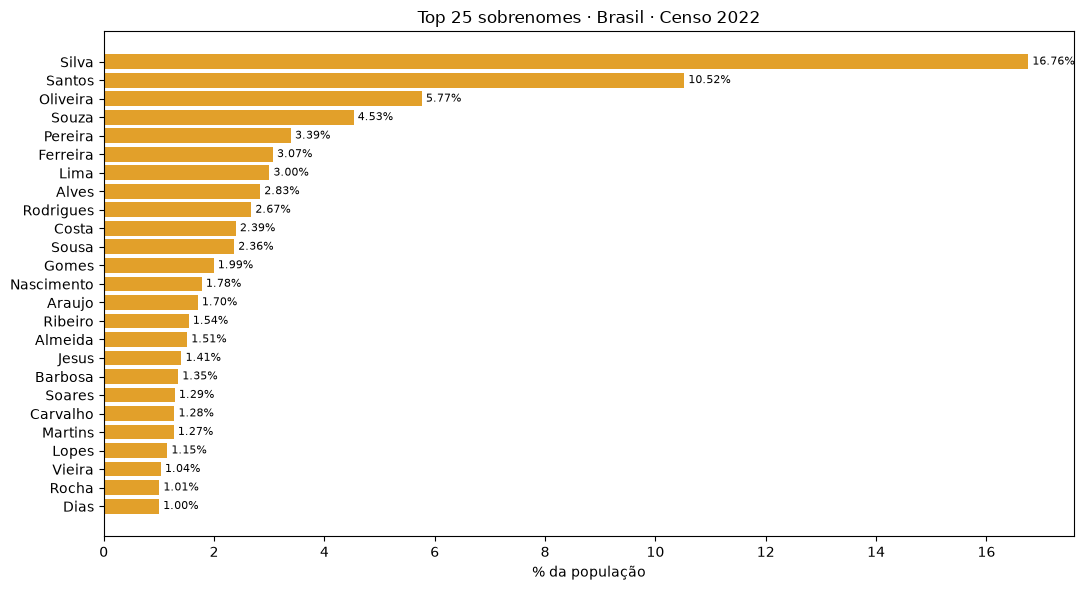

In [3]:
fig, ax = plt.subplots(figsize=(11, 6))
top25 = sob.head(25).iloc[::-1]
bars = ax.barh(top25["nome"].str.title(), top25["percent"], color="#e2a02a")
ax.bar_label(bars, fmt="%.2f%%", fontsize=8, padding=3)
ax.set_title("Top 25 sobrenomes · Brasil · Censo 2022")
ax.set_xlabel("% da população")
plt.tight_layout()
plt.show()

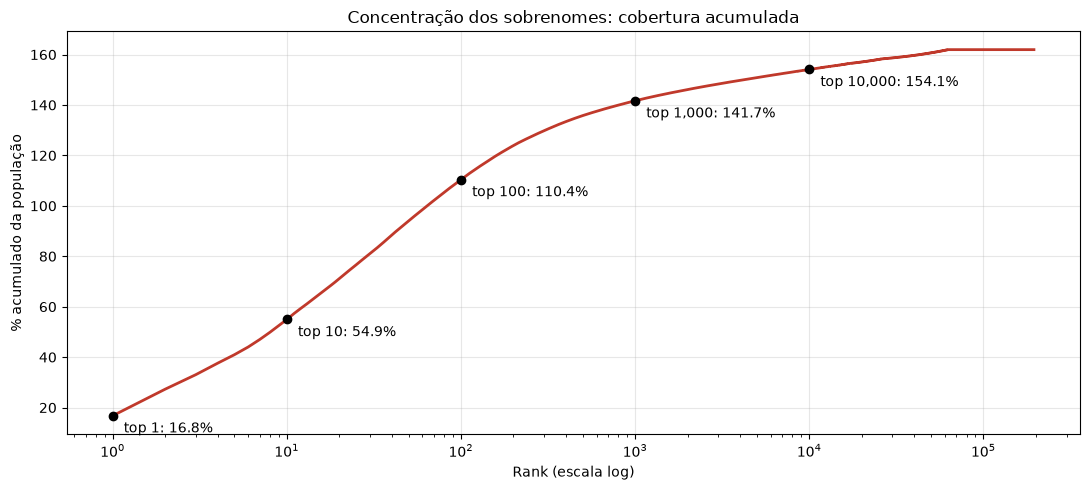

In [4]:
cum = sob["percent"].cumsum()
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sob["rank"], cum, color="#c0392b", lw=2)
for n in (1, 10, 100, 1000, 10000):
    v = cum.iloc[n - 1]
    ax.scatter([n], [v], color="black", zorder=3)
    ax.annotate(f"top {n:,}: {v:.1f}%", (n, v), textcoords="offset points", xytext=(8, -12))
ax.set_xscale("log")
ax.set_xlabel("Rank (escala log)")
ax.set_ylabel("% acumulado da população")
ax.set_title("Concentração dos sobrenomes: cobertura acumulada")
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

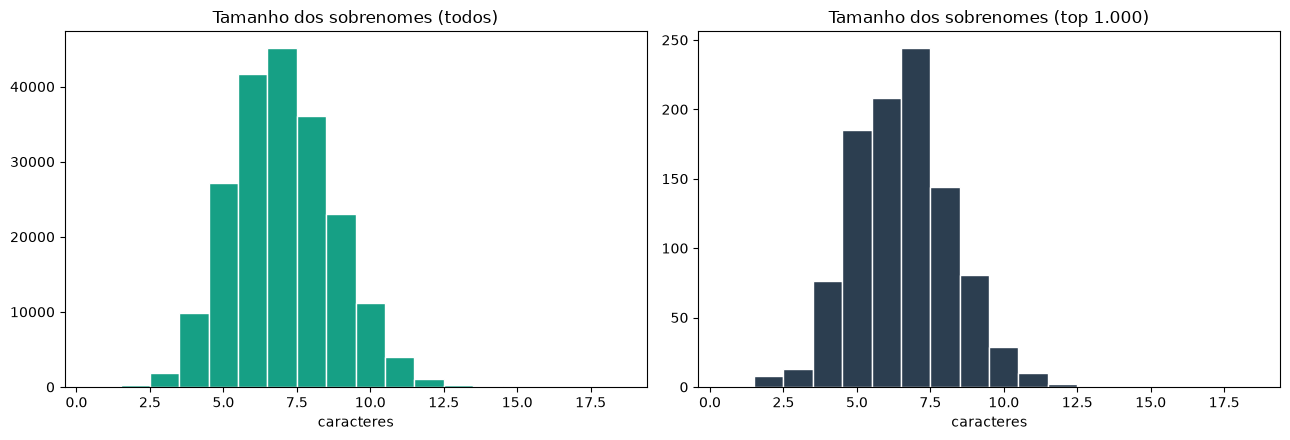

média (todos): 7.03 | média (top 1.000): 6.54


In [5]:
# Length of surnames among the top 1,000 and across the full list
sob["len"] = sob["nome"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(sob["len"], bins=range(1, sob["len"].max() + 2), color="#16a085", edgecolor="white", align="left")
axes[0].set_title("Tamanho dos sobrenomes (todos)")
axes[0].set_xlabel("caracteres")
axes[1].hist(sob.head(1000)["len"], bins=range(1, sob["len"].max() + 2), color="#2c3e50", edgecolor="white", align="left")
axes[1].set_title("Tamanho dos sobrenomes (top 1.000)")
axes[1].set_xlabel("caracteres")
plt.tight_layout()
plt.show()
print("média (todos):", round(sob["len"].mean(), 2), "| média (top 1.000):", round(sob.head(1000)["len"].mean(), 2))